In [1]:
# ============================================
# DATA VORTEX - ROUND 1
# EDA & INSIGHTS
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Project root
BASE_DIR = Path.cwd().parent

# Cleaned dataset path
CLEAN_PATH = (
    BASE_DIR
    / "data"
    / "processed"
    / "posts_cleaned.csv"
)

# Load cleaned data
posts = pd.read_csv(CLEAN_PATH)

# Convert timestamp back to datetime
posts["timestamp"] = pd.to_datetime(
    posts["timestamp"],
    errors="coerce"
)

print("Dataset loaded successfully!")
print("Shape:", posts.shape)
print("\nColumns:")
print(posts.columns.tolist())

Dataset loaded successfully!
Shape: (12000, 8)

Columns:
['post_id', 'user_id', 'platform', 'text_content', 'timestamp', 'likes', 'shares', 'comments']


In [2]:
# ============================================
# 1. PLATFORM-WISE ENGAGEMENT ANALYSIS
# ============================================

# Create engagement metric
posts["engagement"] = (
    posts["likes"].fillna(0)
    + posts["shares"].fillna(0)
    + posts["comments"].fillna(0)
)

# Platform summary
platform_engagement = (
    posts.groupby("platform", dropna=False)
    .agg(
        posts=("post_id", "count"),
        total_likes=("likes", "sum"),
        total_shares=("shares", "sum"),
        total_comments=("comments", "sum"),
        total_engagement=("engagement", "sum"),
        avg_engagement=("engagement", "mean")
    )
    .sort_values("total_engagement", ascending=False)
)

print("Platform Engagement Summary:")
print(platform_engagement)

Platform Engagement Summary:
           posts  total_likes  total_shares  total_comments  total_engagement  \
platform                                                                        
YouTube     2073    4398544.0       2097521         1045580         7541645.0   
Facebook    2074    4438141.0       2041176         1051387         7530704.0   
Reddit      2031    4334296.0       2035527         1038197         7408020.0   
Twitter     2049    4205016.0       2060047         1037053         7302116.0   
Instagram   1989    4234068.0       2070223          994111         7298402.0   
NaN         1784    3772069.0       1781512          885821         6439402.0   

           avg_engagement  
platform                   
YouTube       3638.034250  
Facebook      3631.004822  
Reddit        3647.474151  
Twitter       3563.746218  
Instagram     3669.382604  
NaN           3609.530269  


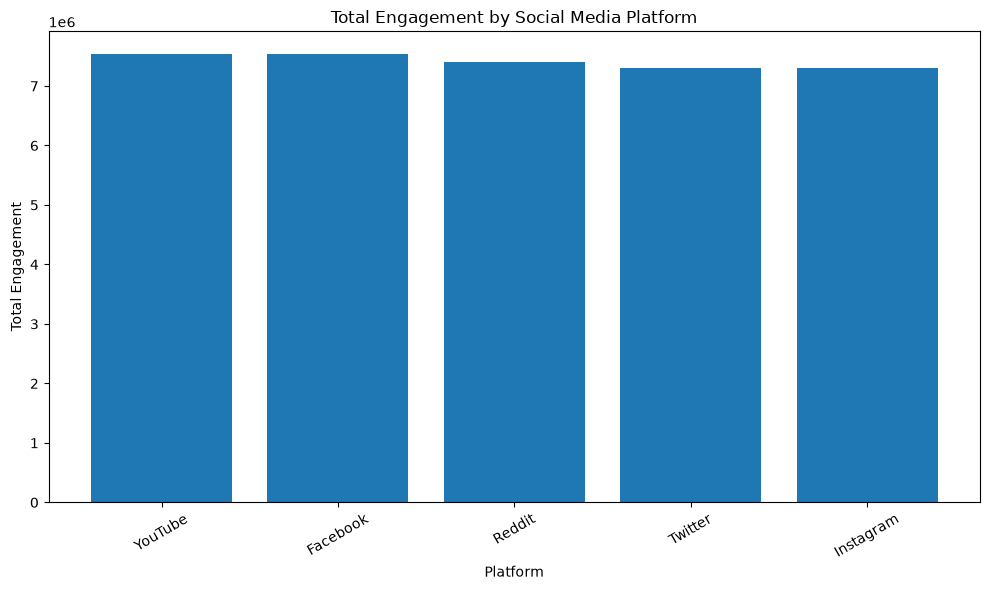

In [3]:
# ============================================
# PLATFORM ENGAGEMENT VISUALIZATION
# ============================================

plot_data = platform_engagement.drop(
    index=[np.nan],
    errors="ignore"
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data.index.astype(str),
    plot_data["total_engagement"]
)

plt.title("Total Engagement by Social Media Platform")
plt.xlabel("Platform")
plt.ylabel("Total Engagement")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [4]:
# ============================================
# TOP PLATFORM INSIGHT
# ============================================

top_platform = platform_engagement[
    platform_engagement.index.notna()
].iloc[0]

print("Highest Total Engagement Platform:")
print("Platform:", platform_engagement[
    platform_engagement.index.notna()
].index[0])

print("Total Engagement:",
      round(top_platform["total_engagement"]))

print("Average Engagement:",
      round(top_platform["avg_engagement"], 2))

Highest Total Engagement Platform:
Platform: YouTube
Total Engagement: 7541645
Average Engagement: 3638.03


In [5]:
# ============================================
# PLATFORM PERFORMANCE COMPARISON
# ============================================

platform_performance = (
    posts.groupby("platform")
    .agg(
        post_count=("post_id", "count"),
        avg_likes=("likes", "mean"),
        avg_shares=("shares", "mean"),
        avg_comments=("comments", "mean"),
        avg_engagement=("engagement", "mean")
    )
    .sort_values("avg_engagement", ascending=False)
)

print("Platform Performance:")
print(platform_performance.round(2))

Platform Performance:
           post_count  avg_likes  avg_shares  avg_comments  avg_engagement
platform                                                                  
Instagram        1989    2500.93     1040.84        499.80         3669.38
Reddit           2031    2488.11     1002.23        511.18         3647.47
YouTube          2073    2517.77     1011.83        504.38         3638.03
Facebook         2074    2528.86      984.17        506.94         3631.00
Twitter          2049    2437.69     1005.39        506.13         3563.75


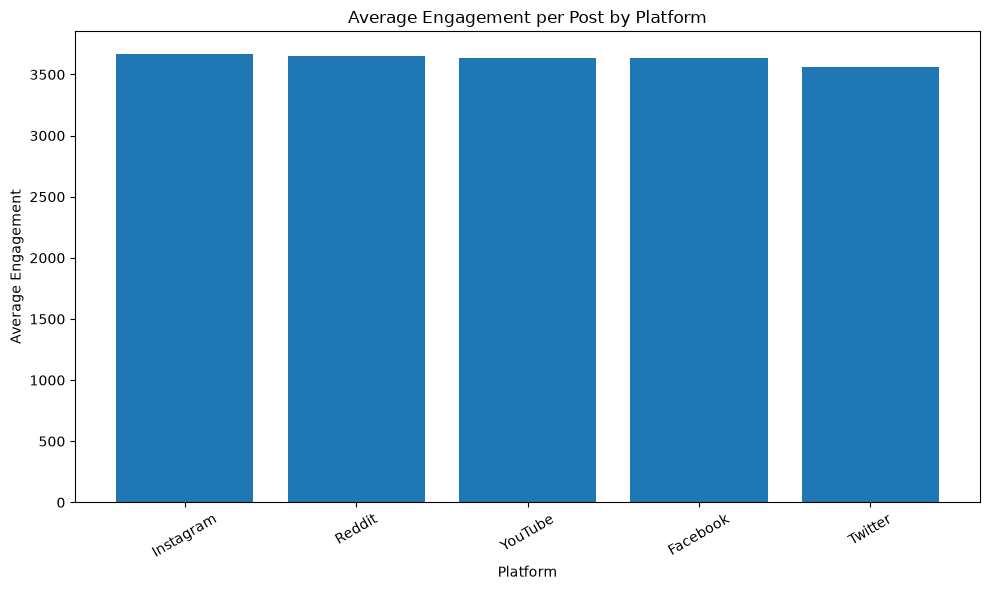

In [6]:
# ============================================
# AVERAGE ENGAGEMENT BY PLATFORM
# ============================================

plt.figure(figsize=(10, 6))

plt.bar(
    platform_performance.index,
    platform_performance["avg_engagement"]
)

plt.title("Average Engagement per Post by Platform")
plt.xlabel("Platform")
plt.ylabel("Average Engagement")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [7]:
# ============================================
# 2. ENGAGEMENT COMPONENT ANALYSIS
# ============================================

engagement_components = pd.Series({
    "Likes": posts["likes"].sum(),
    "Shares": posts["shares"].sum(),
    "Comments": posts["comments"].sum()
})

print("Total Engagement Components:")
print(engagement_components.sort_values(ascending=False))

print("\nPercentage Contribution:")
print(
    (engagement_components /
     engagement_components.sum() * 100)
    .round(2)
)

Total Engagement Components:
Likes       25382134.0
Shares      12086006.0
Comments     6052149.0
dtype: float64

Percentage Contribution:
Likes       58.32
Shares      27.77
Comments    13.91
dtype: float64


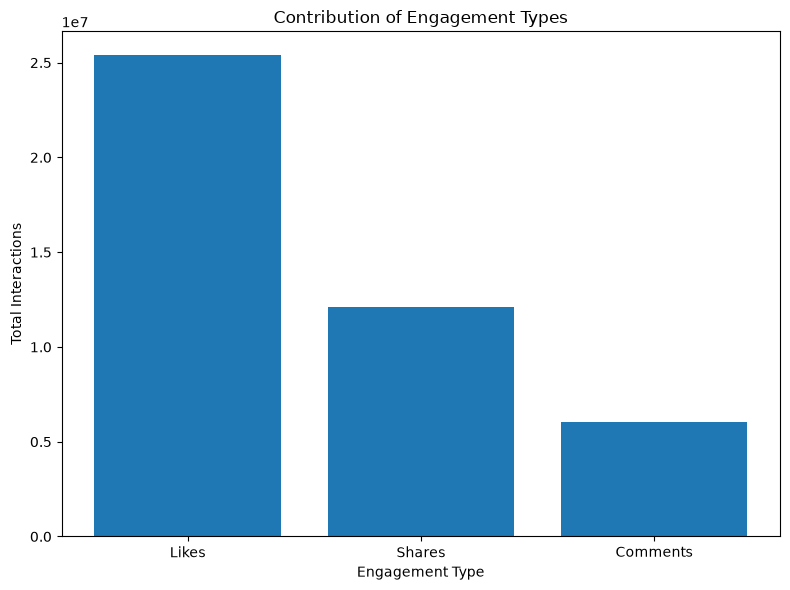

In [8]:
# ============================================
# ENGAGEMENT COMPONENT VISUALIZATION
# ============================================

plt.figure(figsize=(8, 6))

plt.bar(
    engagement_components.index,
    engagement_components.values
)

plt.title("Contribution of Engagement Types")
plt.xlabel("Engagement Type")
plt.ylabel("Total Interactions")

plt.tight_layout()
plt.show()

In [9]:
# ============================================
# 3. ENGAGEMENT COMPONENT ANALYSIS
# ============================================

engagement_components = pd.Series({
    "Likes": posts["likes"].sum(),
    "Shares": posts["shares"].sum(),
    "Comments": posts["comments"].sum()
})

print("Total Engagement Components:")
print(engagement_components.sort_values(ascending=False))

print("\nPercentage Contribution:")
print(
    (engagement_components /
     engagement_components.sum() * 100)
    .round(2)
)

Total Engagement Components:
Likes       25382134.0
Shares      12086006.0
Comments     6052149.0
dtype: float64

Percentage Contribution:
Likes       58.32
Shares      27.77
Comments    13.91
dtype: float64


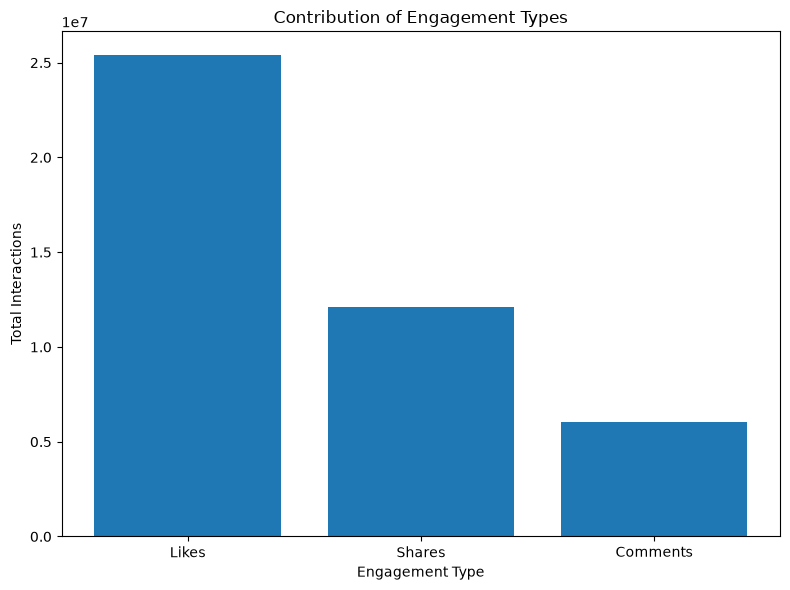

In [10]:
# ============================================
# ENGAGEMENT COMPONENT VISUALIZATION
# ============================================

plt.figure(figsize=(8, 6))

plt.bar(
    engagement_components.index,
    engagement_components.values
)

plt.title("Contribution of Engagement Types")
plt.xlabel("Engagement Type")
plt.ylabel("Total Interactions")

plt.tight_layout()
plt.show()

In [11]:
# ============================================
# 4. ENGAGEMENT CORRELATION ANALYSIS
# ============================================

correlation_data = posts[
    ["likes", "shares", "comments"]
].corr()

print("Correlation Matrix:")
print(correlation_data.round(3))

Correlation Matrix:
          likes  shares  comments
likes     1.000  -0.001     0.010
shares   -0.001   1.000     0.024
comments  0.010   0.024     1.000


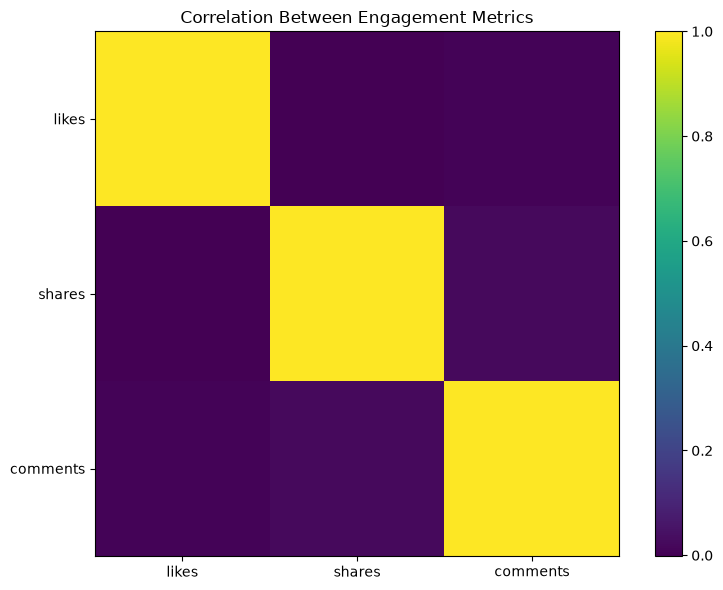

In [12]:
# ============================================
# CORRELATION HEATMAP
# ============================================

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_data,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_data.columns)),
    correlation_data.columns
)

plt.yticks(
    range(len(correlation_data.columns)),
    correlation_data.columns
)

plt.title("Correlation Between Engagement Metrics")

plt.tight_layout()
plt.show()

In [13]:
# ============================================
# 5. TIME-BASED ANALYSIS
# ============================================

posts["year"] = posts["timestamp"].dt.year
posts["month"] = posts["timestamp"].dt.month
posts["month_name"] = posts["timestamp"].dt.month_name()
posts["day_of_week"] = posts["timestamp"].dt.day_name()
posts["hour"] = posts["timestamp"].dt.hour

print("Date range:")
print("Start:", posts["timestamp"].min())
print("End:", posts["timestamp"].max())

print("\nPosts by year:")
print(posts["year"].value_counts().sort_index())

Date range:
Start: 2024-05-01 00:00:00
End: 2025-04-30 21:57:10

Posts by year:
year
2024    8091
2025    3909
Name: count, dtype: int64


In [14]:
# ============================================
# MONTHLY ENGAGEMENT TREND
# ============================================

monthly_engagement = (
    posts.groupby(
        posts["timestamp"].dt.to_period("M")
    )["engagement"]
    .sum()
)

print("Monthly Engagement:")
print(monthly_engagement)

Monthly Engagement:
timestamp
2024-05    3706147.0
2024-06    3455031.0
2024-07    3572824.0
2024-08    3808188.0
2024-09    3521988.0
2024-10    3762245.0
2024-11    3732082.0
2024-12    3793925.0
2025-01    3594403.0
2025-02    3295932.0
2025-03    3742740.0
2025-04    3534784.0
Freq: M, Name: engagement, dtype: float64


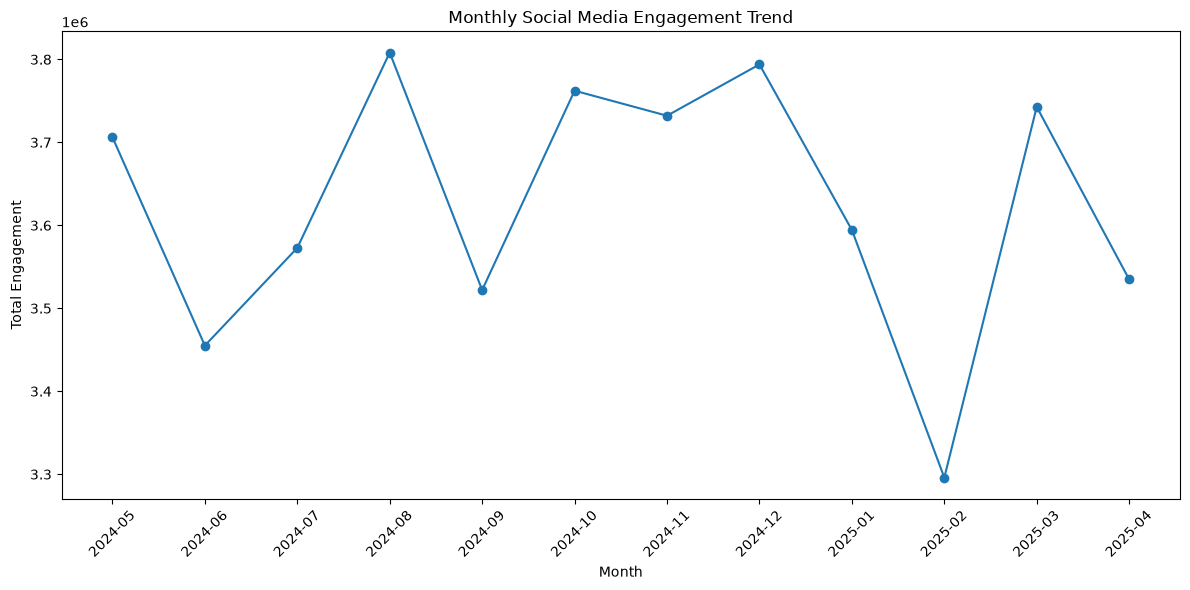

In [15]:
# ============================================
# MONTHLY ENGAGEMENT VISUALIZATION
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_engagement.index.astype(str),
    monthly_engagement.values,
    marker="o"
)

plt.title("Monthly Social Media Engagement Trend")
plt.xlabel("Month")
plt.ylabel("Total Engagement")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# ============================================
# 6. DAY-OF-WEEK ENGAGEMENT
# ============================================

day_engagement = (
    posts.groupby("day_of_week")
    .agg(
        posts=("post_id", "count"),
        total_engagement=("engagement", "sum"),
        avg_engagement=("engagement", "mean")
    )
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_engagement = day_engagement.reindex(day_order)

print(day_engagement.round(2))

             posts  total_engagement  avg_engagement
day_of_week                                         
Monday        1720         6229740.0         3621.94
Tuesday       1677         6023069.0         3591.57
Wednesday     1771         6522222.0         3682.79
Thursday      1718         6204517.0         3611.48
Friday        1723         6175608.0         3584.22
Saturday      1675         6100360.0         3642.01
Sunday        1716         6264773.0         3650.80


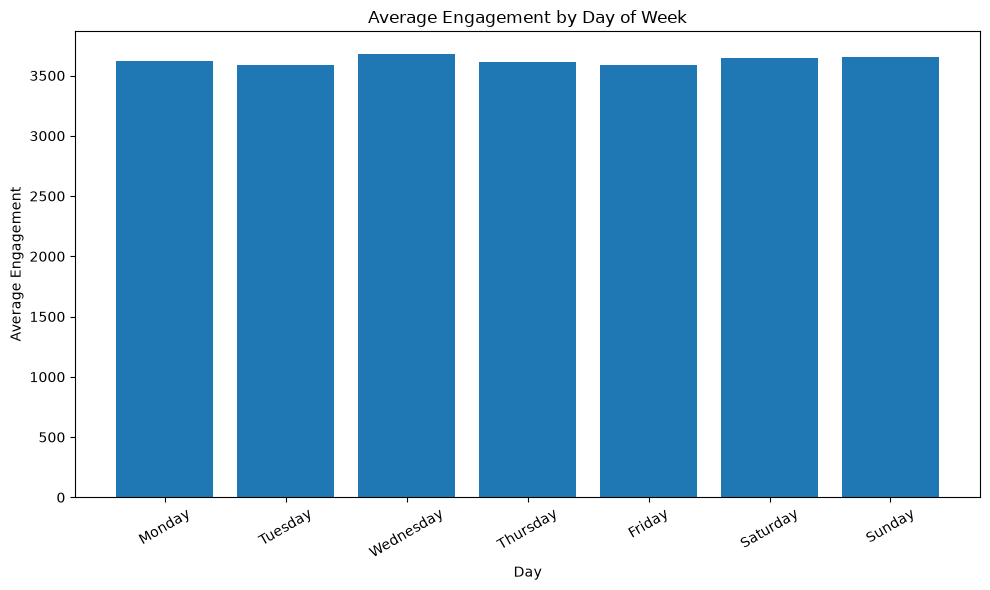

In [17]:
# ============================================
# DAY-OF-WEEK VISUALIZATION
# ============================================

plt.figure(figsize=(10, 6))

plt.bar(
    day_engagement.index,
    day_engagement["avg_engagement"]
)

plt.title("Average Engagement by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Engagement")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [18]:
# ============================================
# 7. POSTING HOUR ANALYSIS
# ============================================

hour_engagement = (
    posts.groupby("hour")
    .agg(
        posts=("post_id", "count"),
        total_engagement=("engagement", "sum"),
        avg_engagement=("engagement", "mean")
    )
    .sort_values("avg_engagement", ascending=False)
)

print("Posting hours ranked by average engagement:")
print(hour_engagement.round(2))

Posting hours ranked by average engagement:
      posts  total_engagement  avg_engagement
hour                                         
1       362         1363675.0         3767.06
23      388         1461129.0         3765.80
20      345         1295078.0         3753.85
17      354         1322651.0         3736.30
5       329         1229039.0         3735.68
19      379         1411563.0         3724.44
9       357         1324323.0         3709.59
21      368         1360816.0         3697.87
4       342         1257623.0         3677.26
3       384         1411511.0         3675.81
10      366         1329546.0         3632.64
2       357         1293289.0         3622.66
15      354         1280609.0         3617.54
14      320         1155473.0         3610.85
8       346         1248532.0         3608.47
0      3902        14075332.0         3607.21
22      351         1260414.0         3590.92
6       344         1233616.0         3586.09
11      348         1246506.0       

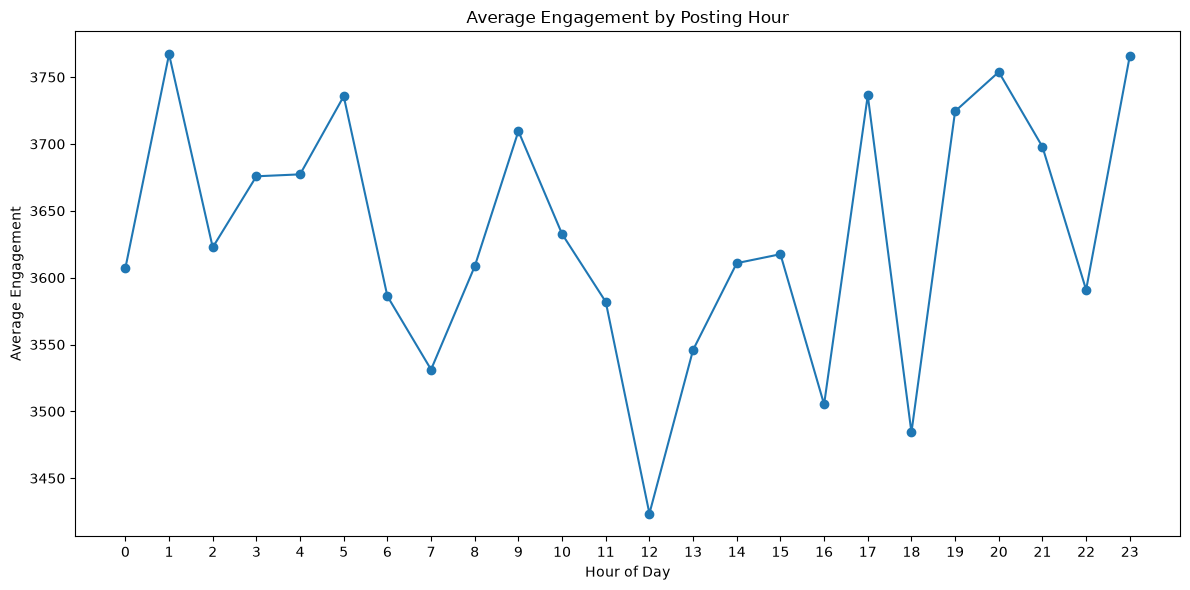

In [19]:
# ============================================
# HOURLY ENGAGEMENT VISUALIZATION
# ============================================

hourly = hour_engagement.sort_index()

plt.figure(figsize=(12, 6))

plt.plot(
    hourly.index,
    hourly["avg_engagement"],
    marker="o"
)

plt.title("Average Engagement by Posting Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Engagement")

plt.xticks(range(24))
plt.tight_layout()
plt.show()

In [20]:
# ============================================
# 8. TOP ENGAGING POSTS
# ============================================

top_posts = posts.sort_values(
    "engagement",
    ascending=False
).head(10)

print(
    top_posts[
        [
            "post_id",
            "platform",
            "likes",
            "shares",
            "comments",
            "engagement",
            "timestamp"
        ]
    ].to_string(index=False)
)

     post_id  platform  likes  shares  comments  engagement           timestamp
ycjj5zzt7mvx Instagram 4983.0    1919       991      7893.0 2025-02-19 05:57:35
wo7py9aljg3t    Reddit 4864.0    1981       948      7793.0 2025-04-28 00:00:00
gmoeib832zbs  Facebook 4902.0    1880       982      7764.0 2025-01-24 10:39:09
5kvuyvf38nqx   YouTube 4923.0    1971       861      7755.0 2024-06-09 00:00:00
pvfl3d8hj7jd Instagram 4989.0    1840       909      7738.0 2024-05-15 00:00:00
tdgjjylpua20       NaN 4979.0    1932       812      7723.0 2024-06-02 00:00:00
tne7s3o4l4wd Instagram 4931.0    1903       878      7712.0 2024-10-30 11:45:55
a1kiwl618kzy  Facebook 4811.0    1952       920      7683.0 2025-04-09 00:00:00
fp89q1ickn9w   Twitter 4740.0    1933       955      7628.0 2025-03-15 18:19:33
5n161ir5hhhr   YouTube 4751.0    1981       878      7610.0 2025-01-26 00:44:23


In [21]:
# ============================================
# 9. PLATFORM × ENGAGEMENT TYPE
# ============================================

platform_components = (
    posts.groupby("platform")
    [["likes", "shares", "comments"]]
    .mean()
    .round(2)
)

print("Average engagement components by platform:")
print(platform_components)

Average engagement components by platform:
             likes   shares  comments
platform                             
Facebook   2528.86   984.17    506.94
Instagram  2500.93  1040.84    499.80
Reddit     2488.11  1002.23    511.18
Twitter    2437.69  1005.39    506.13
YouTube    2517.77  1011.83    504.38


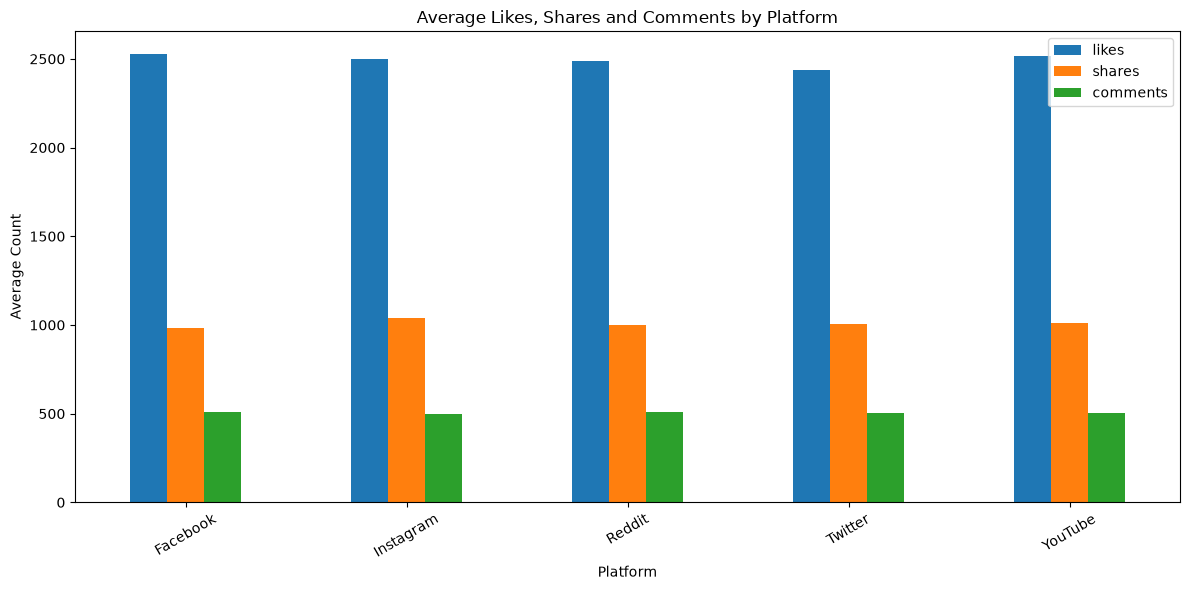

In [22]:
# ============================================
# PLATFORM ENGAGEMENT COMPONENTS
# ============================================

platform_components.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Likes, Shares and Comments by Platform")
plt.xlabel("Platform")
plt.ylabel("Average Count")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:
# ============================================
# 10. USER ENGAGEMENT ANALYSIS
# ============================================

user_engagement = (
    posts.groupby("user_id")
    .agg(
        posts=("post_id", "count"),
        total_engagement=("engagement", "sum"),
        avg_engagement=("engagement", "mean"),
        total_likes=("likes", "sum"),
        total_shares=("shares", "sum"),
        total_comments=("comments", "sum")
    )
    .sort_values(
        "total_engagement",
        ascending=False
    )
)

print("Top 10 users by total engagement:")
print(user_engagement.head(10).round(2))

Top 10 users by total engagement:
               posts  total_engagement  avg_engagement  total_likes  \
user_id                                                               
user_zqv2vrf5     22           83224.0         3782.91      48142.0   
user_nfo3ih5u     19           71529.0         3764.68      41718.0   
user_0irp4abu     17           66967.0         3939.24      43532.0   
user_uerv85na     16           64753.0         4047.06      38094.0   
user_2ytzut7i     14           64710.0         4622.14      40106.0   
user_d4eat3v3     15           64208.0         4280.53      39980.0   
user_ujllj1n7     16           64082.0         4005.12      39729.0   
user_gq0rypar     15           63267.0         4217.80      39004.0   
user_fgjkkrie     14           62690.0         4477.86      39015.0   
user_9mtets0p     14           62414.0         4458.14      39741.0   

               total_shares  total_comments  
user_id                                      
user_zqv2vrf5        

Engagement statistics:
count    12000.00
mean      3626.69
std       1724.30
min         43.00
25%       2197.00
50%       3560.00
75%       5017.00
max       7893.00
Name: engagement, dtype: float64


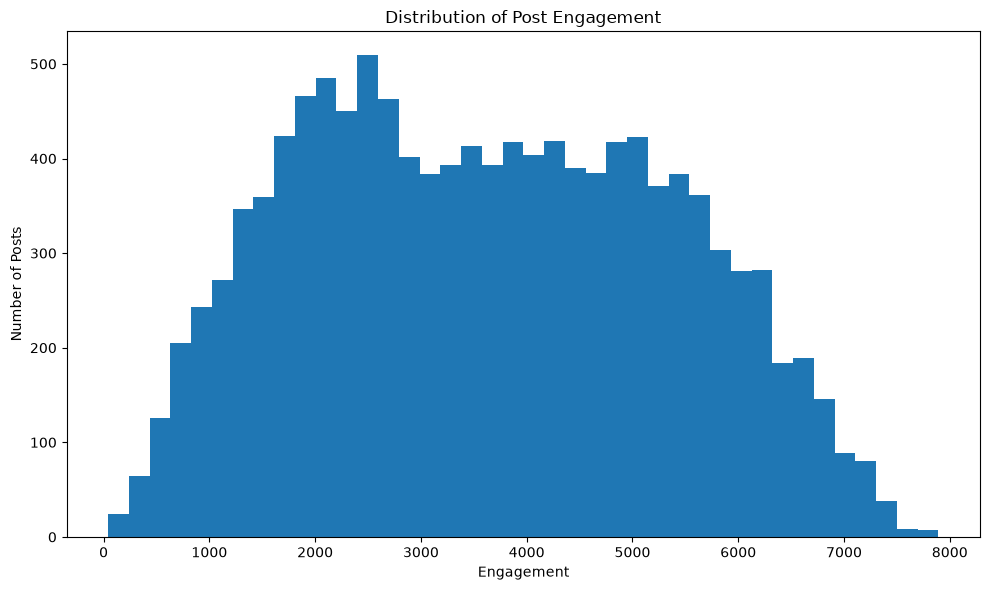

In [24]:
# ============================================
# 11. ENGAGEMENT DISTRIBUTION
# ============================================

print("Engagement statistics:")
print(posts["engagement"].describe().round(2))

plt.figure(figsize=(10, 6))

plt.hist(
    posts["engagement"],
    bins=40
)

plt.title("Distribution of Post Engagement")
plt.xlabel("Engagement")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

In [25]:
# ============================================
# 12. ENGAGEMENT OUTLIER ANALYSIS
# ============================================

Q1 = posts["engagement"].quantile(0.25)
Q3 = posts["engagement"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = posts[
    (posts["engagement"] < lower_bound) |
    (posts["engagement"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("\nLower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nNumber of engagement outliers:", len(outliers))

print("\nTop engagement outliers:")
print(
    outliers[
        [
            "post_id",
            "platform",
            "likes",
            "shares",
            "comments",
            "engagement"
        ]
    ]
    .sort_values("engagement", ascending=False)
    .head(10)
    .to_string(index=False)
)

Q1: 2197.0
Q3: 5017.0
IQR: 2820.0

Lower bound: -2033.0
Upper bound: 9247.0

Number of engagement outliers: 0

Top engagement outliers:
Empty DataFrame
Columns: [post_id, platform, likes, shares, comments, engagement]
Index: []


In [26]:
# ============================================
# 13. FINAL MISSING DATA SUMMARY
# ============================================

missing_summary = pd.DataFrame({
    "missing_count": posts.isna().sum(),
    "missing_percentage": (
        posts.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values(
    "missing_count",
    ascending=False
)

print("Remaining missing values:")
print(missing_summary)

Remaining missing values:
              missing_count  missing_percentage
likes                  1814               15.12
platform               1784               14.87
text_content           1688               14.07


In [27]:
# ============================================
# 14. EDA SUMMARY
# ============================================

valid_platforms = posts[
    posts["platform"].notna()
]

top_platform_total = (
    platform_engagement[
        platform_engagement.index.notna()
    ]
    .sort_values(
        "total_engagement",
        ascending=False
    )
    .index[0]
)

top_platform_average = (
    platform_performance
    .sort_values(
        "avg_engagement",
        ascending=False
    )
    .index[0]
)

top_day = (
    day_engagement["avg_engagement"]
    .idxmax()
)

top_hour = (
    hour_engagement["avg_engagement"]
    .idxmax()
)

top_component = (
    engagement_components
    .idxmax()
)

print("=" * 60)
print("DATA VORTEX - EDA KEY FINDINGS")
print("=" * 60)

print("\nTotal Posts:", len(posts))

print(
    "\nHighest total engagement platform:",
    top_platform_total
)

print(
    "Highest average engagement platform:",
    top_platform_average
)

print(
    "Highest engagement day:",
    top_day
)

print(
    "Highest engagement hour:",
    top_hour
)

print(
    "Dominant engagement type:",
    top_component
)

print(
    "\nNumber of engagement outliers:",
    len(outliers)
)

print("=" * 60)

DATA VORTEX - EDA KEY FINDINGS

Total Posts: 12000

Highest total engagement platform: YouTube
Highest average engagement platform: Instagram
Highest engagement day: Wednesday
Highest engagement hour: 1
Dominant engagement type: Likes

Number of engagement outliers: 0


In [28]:
# ============================================
# CORRECT ENGAGEMENT METRIC
# ============================================
# Missing likes are unknown, NOT zero.
# Therefore, complete engagement is calculated
# only when all three metrics are available.

posts["engagement_complete"] = (
    posts["likes"]
    + posts["shares"]
    + posts["comments"]
)

# Keep engagement as NaN if any component is missing
posts.loc[
    posts[["likes", "shares", "comments"]].isna().any(axis=1),
    "engagement_complete"
] = np.nan

print("Total posts:", len(posts))
print(
    "Posts with complete engagement:",
    posts["engagement_complete"].notna().sum()
)
print(
    "Posts with incomplete engagement:",
    posts["engagement_complete"].isna().sum()
)

Total posts: 12000
Posts with complete engagement: 10186
Posts with incomplete engagement: 1814


In [29]:
# ============================================
# PLATFORM ENGAGEMENT - COMPLETE RECORDS
# ============================================

platform_complete = (
    posts.groupby("platform")
    .agg(
        posts=("post_id", "count"),
        complete_engagement_posts=(
            "engagement_complete",
            "count"
        ),
        avg_engagement=(
            "engagement_complete",
            "mean"
        ),
        total_engagement=(
            "engagement_complete",
            "sum"
        )
    )
    .sort_values(
        "avg_engagement",
        ascending=False
    )
)

print(platform_complete.round(2))

           posts  complete_engagement_posts  avg_engagement  total_engagement
platform                                                                     
Instagram   1989                       1693         4040.02         6839754.0
YouTube     2073                       1747         4031.84         7043632.0
Facebook    2074                       1755         4015.99         7048060.0
Reddit      2031                       1742         4003.94         6974865.0
Twitter     2049                       1725         3951.91         6817045.0


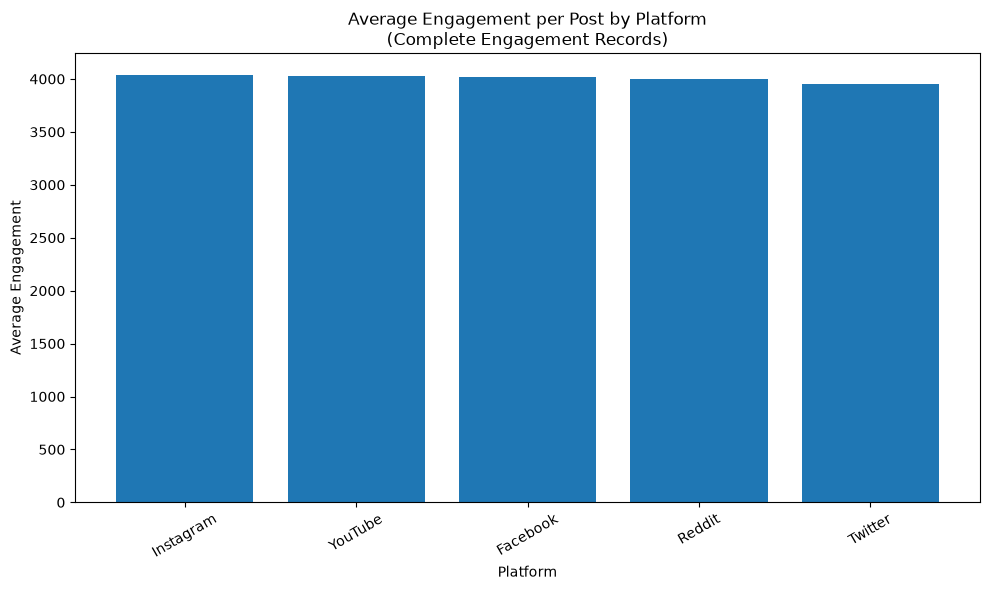

In [30]:
# ============================================
# CORRECTED PLATFORM ENGAGEMENT CHART
# ============================================

plt.figure(figsize=(10, 6))

plt.bar(
    platform_complete.index,
    platform_complete["avg_engagement"]
)

plt.title(
    "Average Engagement per Post by Platform\n"
    "(Complete Engagement Records)"
)

plt.xlabel("Platform")
plt.ylabel("Average Engagement")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [31]:
# ============================================
# 15. DAY × HOUR ENGAGEMENT ANALYSIS
# ============================================

day_hour_engagement = (
    posts.groupby(
        ["day_of_week", "hour"]
    )["engagement_complete"]
    .mean()
    .unstack()
)

day_hour_engagement = day_hour_engagement.reindex(
    [
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ]
)

print("Average engagement by day and hour:")
print(day_hour_engagement.round(2))

Average engagement by day and hour:
hour              0        1        2        3        4        5        6   \
day_of_week                                                                  
Monday       3935.46  4085.62  3646.25  3893.91  3926.79  4179.73  3731.81   
Tuesday      3921.35  4411.59  4123.69  4157.32  3765.66  3817.38  3797.16   
Wednesday    4030.42  4151.56  3886.38  3848.47  4598.87  4153.67  4384.68   
Thursday     4026.15  4250.44  4499.42  4158.79  3592.38  3928.29  4072.20   
Friday       4012.10  4002.90  3904.81  3769.45  4061.82  4197.18  4063.62   
Saturday     4029.09  4135.78  3992.39  4282.82  4037.14  4280.85  3750.00   
Sunday       4044.62  4357.43  4051.28  3958.45  4147.44  3854.93  4239.31   

hour              7        8        9   ...       14       15       16  \
day_of_week                             ...                              
Monday       4174.36  4279.22  3927.95  ...  4216.78  4344.31  4135.29   
Tuesday      4254.41  3730.86  3981.81 

In [32]:
# ============================================
# BEST DAY × HOUR COMBINATION
# ============================================

best_day_hour = (
    day_hour_engagement
    .stack()
    .sort_values(ascending=False)
)

print("Top 10 Day × Hour combinations:")
print(best_day_hour.head(10).round(2))

Top 10 Day × Hour combinations:
day_of_week  hour
Wednesday    4       4598.87
Saturday     20      4533.97
Thursday     2       4499.42
Sunday       20      4495.81
Friday       11      4468.13
Sunday       23      4442.81
Wednesday    19      4420.70
Tuesday      1       4411.59
Wednesday    18      4409.62
             6       4384.68
dtype: float64


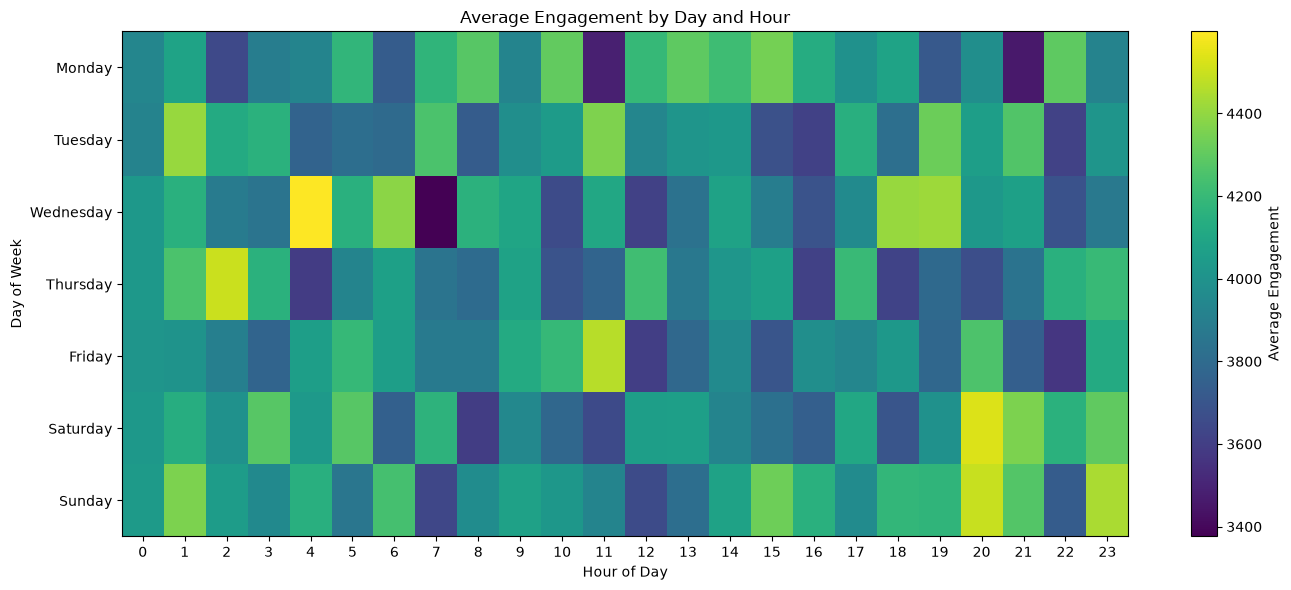

In [33]:
# ============================================
# DAY × HOUR HEATMAP
# ============================================

plt.figure(figsize=(14, 6))

plt.imshow(
    day_hour_engagement,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Average Engagement")

plt.xticks(
    range(24),
    range(24)
)

plt.yticks(
    range(7),
    day_hour_engagement.index
)

plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.title("Average Engagement by Day and Hour")

plt.tight_layout()
plt.show()

In [34]:
# ============================================
# 16. POSTING VOLUME VS ENGAGEMENT
# ============================================

hour_summary = (
    posts.groupby("hour")
    .agg(
        post_count=("post_id", "count"),
        avg_engagement=("engagement_complete", "mean")
    )
    .round(2)
)

print("Posting volume vs average engagement:")
print(hour_summary)

Posting volume vs average engagement:
      post_count  avg_engagement
hour                            
0           3902         4000.96
1            362         4187.29
2            357         4021.09
3            384         4010.56
4            342         4019.24
5            329         4042.31
6            344         4010.60
7            340         3917.11
8            346         3932.90
9            357         4033.74
10           366         3933.44
11           348         3935.11
12           360         3897.44
13           352         3959.41
14           320         4051.56
15           354         3971.40
16           311         3850.47
17           354         4045.56
18           341         3961.01
19           379         4058.92
20           345         4134.31
21           368         4021.42
22           351         3888.51
23           388         4135.33


In [35]:
# ============================================
# VALIDATE TOP DAY × HOUR SLOTS
# ============================================

day_hour_counts = (
    posts.groupby(
        ["day_of_week", "hour"]
    )
    .agg(
        post_count=("post_id", "count"),
        complete_engagement_posts=(
            "engagement_complete",
            "count"
        ),
        avg_engagement=(
            "engagement_complete",
            "mean"
        )
    )
)

top_slots = (
    day_hour_counts
    .sort_values("avg_engagement", ascending=False)
    .head(10)
)

print("Top 10 Day × Hour slots with sample size:")
print(top_slots.round(2))

Top 10 Day × Hour slots with sample size:
                  post_count  complete_engagement_posts  avg_engagement
day_of_week hour                                                       
Wednesday   4             52                         46         4598.87
Saturday    20            42                         37         4533.97
Thursday    2             49                         40         4499.42
Sunday      20            43                         37         4495.81
Friday      11            45                         38         4468.13
Sunday      23            54                         47         4442.81
Wednesday   19            62                         56         4420.70
Tuesday     1             40                         34         4411.59
Wednesday   18            34                         32         4409.62
            6             54                         47         4384.68


In [36]:
# ============================================
# RELIABLE HIGH-ENGAGEMENT TIME SLOTS
# ============================================

reliable_slots = (
    day_hour_counts[
        day_hour_counts["complete_engagement_posts"] >= 50
    ]
    .sort_values(
        "avg_engagement",
        ascending=False
    )
    .head(10)
)

print("Top reliable Day × Hour slots:")
print(reliable_slots.round(2))

Top reliable Day × Hour slots:
                  post_count  complete_engagement_posts  avg_engagement
day_of_week hour                                                       
Wednesday   19            62                         56         4420.70
Saturday    21            61                         52         4355.98
Tuesday     19            55                         50         4323.54
Monday      22            63                         54         4296.59
            8             57                         50         4279.22
Tuesday     21            54                         50         4267.90
Thursday    23            61                         55         4201.47
Monday      12            60                         52         4196.77
Sunday      19            63                         51         4176.14
Wednesday   1             65                         55         4151.56


In [38]:
# ============================================
# 17. USER-LEVEL BEHAVIOR ANALYSIS
# ============================================

# Load users dataset
USERS_PATH = (
    BASE_DIR
    / "data"
    / "raw"
    / "Social_Engine_Users.csv"
)

users = pd.read_csv(USERS_PATH)

print("Users dataset loaded:", users.shape)

# Create user-level post engagement summary
user_summary = (
    posts.groupby("user_id")
    .agg(
        post_count=("post_id", "count"),
        avg_engagement=("engagement_complete", "mean"),
        total_engagement=("engagement_complete", "sum"),
        avg_likes=("likes", "mean"),
        avg_shares=("shares", "mean"),
        avg_comments=("comments", "mean")
    )
)

# Add user profile information
user_summary = user_summary.merge(
    users[
        [
            "user_id",
            "location",
            "language",
            "follower_count"
        ]
    ],
    left_index=True,
    right_on="user_id",
    how="left"
)

user_summary = user_summary.set_index("user_id")

print("\nUser-level summary created successfully!")
print("Users analyzed:", len(user_summary))

print("\nSample:")
print(user_summary.head())

Users dataset loaded: (1500, 5)

User-level summary created successfully!
Users analyzed: 1500

Sample:
               post_count  avg_engagement  total_engagement    avg_likes  \
user_id                                                                    
user_00evmn72          11     3669.100000           36691.0  2559.100000   
user_01hav2yk           8     3373.571429           23615.0  1987.714286   
user_01mu2x1s           9     5490.857143           38436.0  3208.428571   
user_0281t7ll          12     2809.400000           28094.0  1585.400000   
user_02sm9ly7           8     3148.750000           25190.0  1708.750000   

                avg_shares  avg_comments                    location language  \
user_id                                                                         
user_00evmn72   610.636364    445.636364  Johannesburg, South Africa       hi   
user_01hav2yk  1105.625000    345.750000            Barcelona, Spain       es   
user_01mu2x1s  1663.555556    525.66666

In [39]:
# ============================================
# TOP USERS BY ENGAGEMENT
# ============================================

top_users = (
    user_summary
    .sort_values(
        "total_engagement",
        ascending=False
    )
    .head(10)
)

print("Top 10 users by total engagement:")
print(
    top_users[
        [
            "post_count",
            "total_engagement",
            "avg_engagement",
            "follower_count",
            "location",
            "language"
        ]
    ].round(2)
)

Top 10 users by total engagement:
               post_count  total_engagement  avg_engagement  follower_count  \
user_id                                                                       
user_zqv2vrf5          22           81326.0         4280.32           13531   
user_nfo3ih5u          19           69109.0         4065.24           40429   
user_0irp4abu          17           64133.0         4580.93           44206   
user_2ytzut7i          14           63888.0         4914.46           17064   
user_fgjkkrie          14           62690.0         4477.86            2211   
user_d4eat3v3          15           62588.0         4470.57           49914   
user_9mtets0p          14           62414.0         4458.14            8262   
user_y9bjiho1          13           61956.0         4765.85           24858   
user_i1e1kek5          16           61112.0         4074.13           46765   
user_gq0rypar          15           60450.0         4650.00           17672   

                 

In [40]:
# ============================================
# FOLLOWER COUNT vs ENGAGEMENT
# ============================================

follower_correlation = user_summary[
    [
        "follower_count",
        "avg_engagement"
    ]
].corr()

print("Follower count vs average engagement:")
print(follower_correlation.round(3))

Follower count vs average engagement:
                follower_count  avg_engagement
follower_count           1.000           0.004
avg_engagement           0.004           1.000


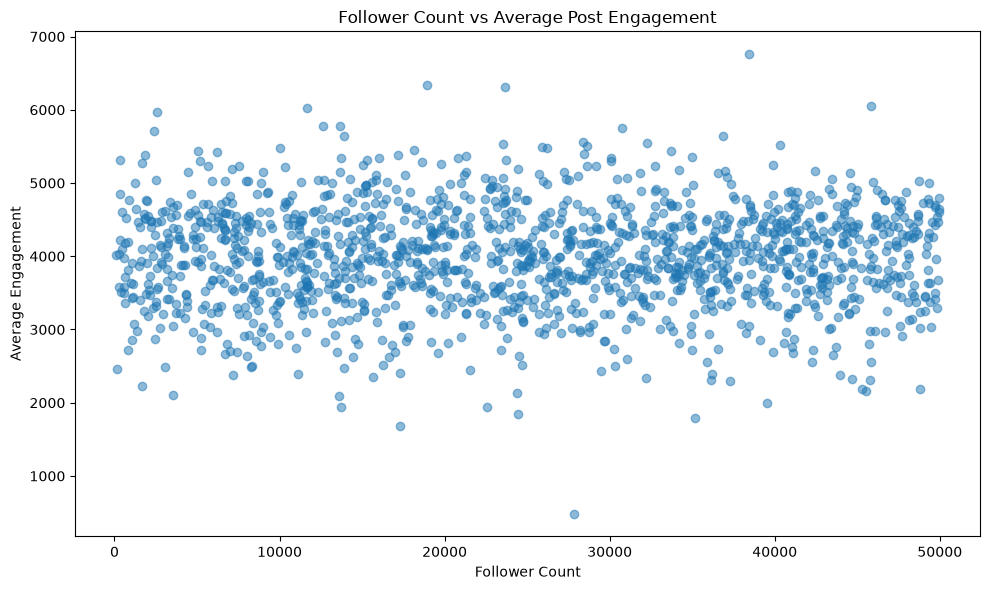

In [41]:
# ============================================
# FOLLOWER COUNT vs AVG ENGAGEMENT
# ============================================

plt.figure(figsize=(10, 6))

plt.scatter(
    user_summary["follower_count"],
    user_summary["avg_engagement"],
    alpha=0.5
)

plt.title(
    "Follower Count vs Average Post Engagement"
)

plt.xlabel("Follower Count")
plt.ylabel("Average Engagement")

plt.tight_layout()
plt.show()

In [42]:
# ============================================
# LOCATION-WISE ENGAGEMENT
# ============================================

location_engagement = (
    user_summary.groupby("location")
    .agg(
        users=("follower_count", "count"),
        avg_followers=("follower_count", "mean"),
        avg_engagement=("avg_engagement", "mean")
    )
    .sort_values(
        "avg_engagement",
        ascending=False
    )
)

print("Top locations by average user engagement:")
print(
    location_engagement.head(15).round(2)
)

Top locations by average user engagement:
                      users  avg_followers  avg_engagement
location                                                  
Barcelona, Spain         56       23975.64         4114.51
Sydney, Australia        28       26618.07         4097.59
Osaka, Japan             50       27564.50         4092.16
Paris, France            45       24723.18         4090.68
Singapore                49       24612.20         4088.28
Melbourne, Australia     52       27374.83         4085.29
Mexico City, Mexico      40       26326.15         4069.35
Dubai, UAE               53       25724.26         4068.23
Cairo, Egypt             39       21908.77         4059.99
Delhi, India             39       29381.23         4058.02
Berlin, Germany          43       26878.14         4054.72
Beijing, China           51       25221.06         4049.14
London, UK               45       21758.07         4042.91
Houston, USA             50       19473.46         4041.69
Toronto, Canad

In [43]:
# ============================================
# LANGUAGE-WISE ENGAGEMENT
# ============================================

language_engagement = (
    user_summary.groupby("language")
    .agg(
        users=("follower_count", "count"),
        avg_followers=("follower_count", "mean"),
        avg_engagement=("avg_engagement", "mean")
    )
    .sort_values(
        "avg_engagement",
        ascending=False
    )
)

print("Language-wise engagement:")
print(
    language_engagement.round(2)
)

Language-wise engagement:
          users  avg_followers  avg_engagement
language                                      
en          153       27000.54         4083.18
ar          143       25584.81         4052.63
pt          143       26066.38         4042.13
zh          168       25028.33         3997.86
ja          156       24547.73         3980.30
de          141       21692.05         3970.79
es          146       22963.95         3958.03
fr          150       25128.08         3956.35
ru          144       26453.28         3949.19
hi          156       25030.89         3933.60


In [44]:
# ============================================
# FINAL EDA DATA QUALITY CHECK
# ============================================

print("=" * 60)
print("FINAL EDA DATA QUALITY CHECK")
print("=" * 60)

print("\nRows:", len(posts))
print("Columns:", len(posts.columns))

print("\nDuplicate rows:", posts.duplicated().sum())
print(
    "Duplicate post IDs:",
    posts["post_id"].duplicated().sum()
)

print(
    "Invalid timestamps:",
    posts["timestamp"].isna().sum()
)

print(
    "Negative likes:",
    (posts["likes"] < 0).sum()
)

print("\nMissing values:")
print(posts.isna().sum())

print("=" * 60)

FINAL EDA DATA QUALITY CHECK

Rows: 12000
Columns: 15

Duplicate rows: 0
Duplicate post IDs: 0
Invalid timestamps: 0
Negative likes: 0

Missing values:
post_id                   0
user_id                   0
platform               1784
text_content           1688
timestamp                 0
likes                  1814
shares                    0
comments                  0
engagement                0
year                      0
month                     0
month_name                0
day_of_week               0
hour                      0
engagement_complete    1814
dtype: int64


In [45]:
# ============================================
# DATA VORTEX - FINAL KEY INSIGHTS
# ============================================

# Platform insight
top_platform_avg = platform_complete["avg_engagement"].idxmax()
top_platform_avg_value = platform_complete["avg_engagement"].max()

# Engagement component insight
top_component = engagement_components.idxmax()
top_component_value = engagement_components.max()
top_component_pct = (
    engagement_components[top_component]
    / engagement_components.sum()
    * 100
)

# Day insight
best_day = day_engagement["avg_engagement"].idxmax()
best_day_value = day_engagement["avg_engagement"].max()

# Reliable time-slot insight
best_reliable_slot = reliable_slots.iloc[0]

# Correlation insight
likes_shares_corr = correlation_data.loc["likes", "shares"]
likes_comments_corr = correlation_data.loc["likes", "comments"]
shares_comments_corr = correlation_data.loc["shares", "comments"]

# User insight
top_user = user_summary["total_engagement"].idxmax()
top_user_engagement = user_summary.loc[
    top_user, "total_engagement"
]

print("=" * 70)
print("DATA VORTEX — ROUND 1 KEY EDA INSIGHTS")
print("=" * 70)

print("\n1. PLATFORM PERFORMANCE")
print(
    f"Highest average engagement platform: "
    f"{top_platform_avg}"
)
print(
    f"Average engagement per post: "
    f"{top_platform_avg_value:.2f}"
)

print("\n2. ENGAGEMENT BEHAVIOR")
print(
    f"Dominant engagement type: {top_component}"
)
print(
    f"Contribution: {top_component_pct:.2f}%"
)

print("\n3. DAY-OF-WEEK PATTERN")
print(
    f"Highest average engagement day: "
    f"{best_day}"
)
print(
    f"Average engagement: {best_day_value:.2f}"
)

print("\n4. RELIABLE POSTING WINDOW")
print(
    f"Best reliable slot: "
    f"{best_reliable_slot.name[0]} "
    f"at {int(best_reliable_slot.name[1]):02d}:00"
)
print(
    f"Average engagement: "
    f"{best_reliable_slot['avg_engagement']:.2f}"
)
print(
    f"Complete posts: "
    f"{int(best_reliable_slot['complete_engagement_posts'])}"
)

print("\n5. ENGAGEMENT CORRELATION")
print(
    f"Likes ↔ Shares: {likes_shares_corr:.3f}"
)
print(
    f"Likes ↔ Comments: {likes_comments_corr:.3f}"
)
print(
    f"Shares ↔ Comments: {shares_comments_corr:.3f}"
)

print("\n6. TOP USER")
print(f"User ID: {top_user}")
print(
    f"Total engagement: "
    f"{top_user_engagement:.0f}"
)

print("\n7. DATA QUALITY")
print(f"Final posts: {len(posts)}")
print(
    f"Duplicate rows: "
    f"{posts.duplicated().sum()}"
)
print(
    f"Duplicate post IDs: "
    f"{posts['post_id'].duplicated().sum()}"
)
print(
    f"Negative likes: "
    f"{(posts['likes'] < 0).sum()}"
)

print("=" * 70)

DATA VORTEX — ROUND 1 KEY EDA INSIGHTS

1. PLATFORM PERFORMANCE
Highest average engagement platform: Instagram
Average engagement per post: 4040.02

2. ENGAGEMENT BEHAVIOR
Dominant engagement type: Likes
Contribution: 58.32%

3. DAY-OF-WEEK PATTERN
Highest average engagement day: Wednesday
Average engagement: 3682.79

4. RELIABLE POSTING WINDOW
Best reliable slot: Wednesday at 19:00
Average engagement: 4420.70
Complete posts: 56

5. ENGAGEMENT CORRELATION
Likes ↔ Shares: -0.001
Likes ↔ Comments: 0.010
Shares ↔ Comments: 0.024

6. TOP USER
User ID: user_zqv2vrf5
Total engagement: 81326

7. DATA QUALITY
Final posts: 12000
Duplicate rows: 0
Duplicate post IDs: 0
Negative likes: 0


In [46]:
# ============================================
# EXPORT EDA SUMMARY
# ============================================

EDA_OUTPUT_DIR = BASE_DIR / "data" / "processed" / "eda"
EDA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

eda_summary = pd.DataFrame({
    "metric": [
        "total_posts",
        "highest_avg_engagement_platform",
        "highest_avg_engagement",
        "dominant_engagement_type",
        "dominant_engagement_percentage",
        "highest_engagement_day",
        "highest_day_avg_engagement",
        "best_reliable_day",
        "best_reliable_hour",
        "best_reliable_avg_engagement",
        "likes_shares_correlation",
        "likes_comments_correlation",
        "shares_comments_correlation",
        "duplicate_rows",
        "duplicate_post_ids",
        "negative_likes"
    ],
    "value": [
        len(posts),
        top_platform_avg,
        round(top_platform_avg_value, 2),
        top_component,
        round(top_component_pct, 2),
        best_day,
        round(best_day_value, 2),
        best_reliable_slot.name[0],
        int(best_reliable_slot.name[1]),
        round(best_reliable_slot["avg_engagement"], 2),
        round(likes_shares_corr, 3),
        round(likes_comments_corr, 3),
        round(shares_comments_corr, 3),
        posts.duplicated().sum(),
        posts["post_id"].duplicated().sum(),
        (posts["likes"] < 0).sum()
    ]
})

EDA_SUMMARY_PATH = EDA_OUTPUT_DIR / "eda_summary.csv"

eda_summary.to_csv(
    EDA_SUMMARY_PATH,
    index=False
)

print("EDA summary saved successfully!")
print("File:", EDA_SUMMARY_PATH)

EDA summary saved successfully!
File: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\data\processed\eda\eda_summary.csv


In [47]:
# ============================================
# EXPORT PLATFORM ANALYSIS
# ============================================

PLATFORM_OUTPUT = EDA_OUTPUT_DIR / "platform_analysis.csv"

platform_complete.to_csv(PLATFORM_OUTPUT)

print("Platform analysis saved!")
print("File:", PLATFORM_OUTPUT)

Platform analysis saved!
File: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\data\processed\eda\platform_analysis.csv


In [48]:
# ============================================
# EXPORT TIME ANALYSIS
# ============================================

TIME_OUTPUT = EDA_OUTPUT_DIR / "day_hour_analysis.csv"

day_hour_counts.to_csv(TIME_OUTPUT)

print("Day × Hour analysis saved!")
print("File:", TIME_OUTPUT)

Day × Hour analysis saved!
File: c:\Users\Jivan\OneDrive\Desktop\projectS\DATA-VORTEX-SOCIAL-ENGINE\data\processed\eda\day_hour_analysis.csv
